In [2]:
import torch
import torchvision 
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset, ConcatDataset
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os

In [9]:
file_list = os.listdir("./data/custom")
cat_files = [file_name for file_name in file_list if 'cat' in file_name]
dog_files = [file_name for file_name in file_list if 'dog' in file_name]

In [10]:
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

In [11]:
class CatDogDataset(Dataset):
    def __init__(self, file_list, dir, transform=None):
        self.file_list = file_list
        self.dir = dir
        self.transform = transform
        if "dog" in self.file_list[0]:
            self.label = 1
        else:
            self.label = 0

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        file_path = os.path.join(self.dir, self.file_list[idx])
        img = Image.open(file_path)
        if self.transform is not None:
            img = self.transform(img)
        return img, self.label

In [12]:
dir_path = "./data/custom/"
cat_dataset = CatDogDataset(cat_files, dir_path, transform=transform)
dog_dataset = CatDogDataset(dog_files, dir_path, transform=transform)

cat_dog_dataset = ConcatDataset([cat_dataset, dog_dataset])

In [13]:
data_loader = DataLoader(cat_dog_dataset, batch_size=32, shuffle=True)

In [15]:
data_iter = iter(data_loader)
imgs, labels = next(data_iter)
imgs.size(), labels

(torch.Size([32, 3, 256, 256]),
 tensor([1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0,
         0, 0, 1, 0, 0, 0, 0, 0]))

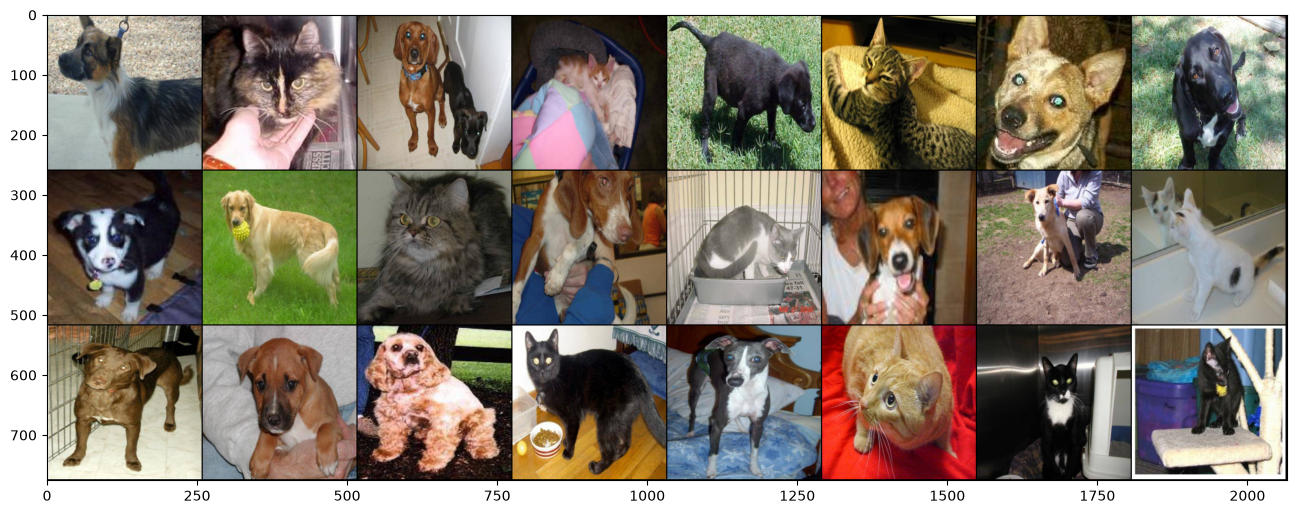

In [17]:
grid_imgs = torchvision.utils.make_grid(imgs[:24])
grid_imgs_arr = grid_imgs.numpy()
plt.figure(figsize=(16, 24))
plt.imshow(np.transpose(grid_imgs_arr, (1, 2, 0)))